# Частота продаж по ассортименту

**Цель:** Проанализировать, сколько месяцев каждый SKU имел ненулевые продажи за 12 месяцев; изучить распределение частоты продаж и выявить неликвидные и регулярные позиции.

**Вход:** `valtec_df_common.xlsx` (не приложен).

**Основные шаги:** помесячная агрегация, подсчёт частоты, графики распределения.

**Навыки:** pandas, groupby, matplotlib.

In [1]:
import pandas as pd

In [20]:
import matplotlib.pyplot as plt

In [74]:
valtec_df_common = pd.read_excel('valtec_df_common.xlsx')

In [75]:
valtec_df_common['Месяц'] = valtec_df_common['Дата'].dt.month

In [76]:
valtec_df_common_12 = valtec_df_common[((valtec_df_common['Год'] == 2024)&(valtec_df_common['Месяц'] >= 4 )) | (valtec_df_common['Год'] == 2025)]

In [77]:
valtec_df_common_12 = valtec_df_common_12[valtec_df_common_12['Категория'] != 1]

In [78]:
# Группируем по товару и считаем, в скольких месяцах Расход_шт > 0
sales_count = valtec_df_common_12[valtec_df_common_12['Расход_шт'] > 0] \
    .groupby('Код')['Расход_шт'].count().reset_index()

sales_count.rename(columns={'Расход_шт': 'Кол_во_продаж'}, inplace=True)

# Присоединяем этот столбец к исходному датафрейму
valtec_df_common_12 = valtec_df_common_12.merge(sales_count, on='Код', how='left')

# Если где-то не было ни одной продажи, подставим 0
valtec_df_common_12['Кол_во_продаж'] = valtec_df_common_12['Кол_во_продаж'].fillna(0).astype(int)


In [65]:
valtec_df_common_12

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток,Выручка,Категория,...,Артикул,Начальный_остаток_шт,Расход_шт,Приход_шт,Квартал,ABC_valtec,XYZ_valtec,Месяц,Кол_во_продаж_x,Кол_во_продаж_y
0,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-08-01,1155.00,525.00,1575.00,105.00,1840.05,1,...,VTr.198.C.0410,22.0,30.0,10,3,B,X,8,30.0,10.0
1,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-04-01,1732.21,0.00,1732.21,0.00,2055.37,1,...,VTr.198.C.0410,33.0,33.0,0,2,B,X,4,33.0,10.0
2,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-12-01,577.50,1826.67,2404.17,0.00,2936.81,1,...,VTr.198.C.0410,11.0,41.0,30,4,B,X,12,41.0,10.0
3,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-07-01,0.00,2100.00,945.00,1155.00,1100.11,1,...,VTr.198.C.0410,0.0,18.0,40,3,B,X,7,18.0,10.0
4,00-00000184,Удлинитель 1/2 10 мм кругл. Valtec.(30) СКЛАД...,шт,2024-06-01,525.00,1575.00,2100.00,0.00,2362.05,1,...,VTr.198.C.0410,10.0,40.0,30,2,B,X,6,40.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9475,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2024-11-01,86.33,0.00,0.00,86.33,0.00,2,...,VT.141.0.04,4.0,0.0,0,4,C,Z,11,0.0,1.0
9476,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2024-10-01,0.00,25684.16,25597.83,86.33,32120.83,2,...,VT.141.0.04,0.0,1186.0,1190,4,C,Z,10,1186.0,1.0
9477,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2024-09-01,0.00,0.00,0.00,0.00,0.00,2,...,VT.141.0.04,0.0,0.0,0,3,C,Z,9,0.0,1.0
9478,0Т-00054517,"яКлапан обратный 1/2"" для водосчетчика (под сг...",шт,2025-02-01,86.33,0.00,0.00,86.33,0.00,2,...,VT.141.0.04,4.0,0.0,0,1,C,Z,2,0.0,1.0


In [85]:
valtec_df_common_12[valtec_df_common_12['Кол_во_продаж'] > 5]['Код'].nunique()

12

In [80]:
valtec_df_common_12['Код'].nunique()

537

In [58]:
790 - 253

537

In [59]:
790 - 495

295

In [15]:
sales_count['Частота'] = (sales_count['Кол_во_продаж'] / 12) * 100

In [17]:
sales_count.describe()

,Кол_во_продаж,Частота
count,495.000000,495.000000
mean,4.436364,36.969697
std,3.630657,30.255476
min,1.000000,8.333333
25%,1.000000,8.333333
50%,3.000000,25.000000
75%,7.000000,58.333333
max,12.000000,100.000000


In [18]:
sales_count = sales_count.sort_values('Частота').reset_index(drop=True)

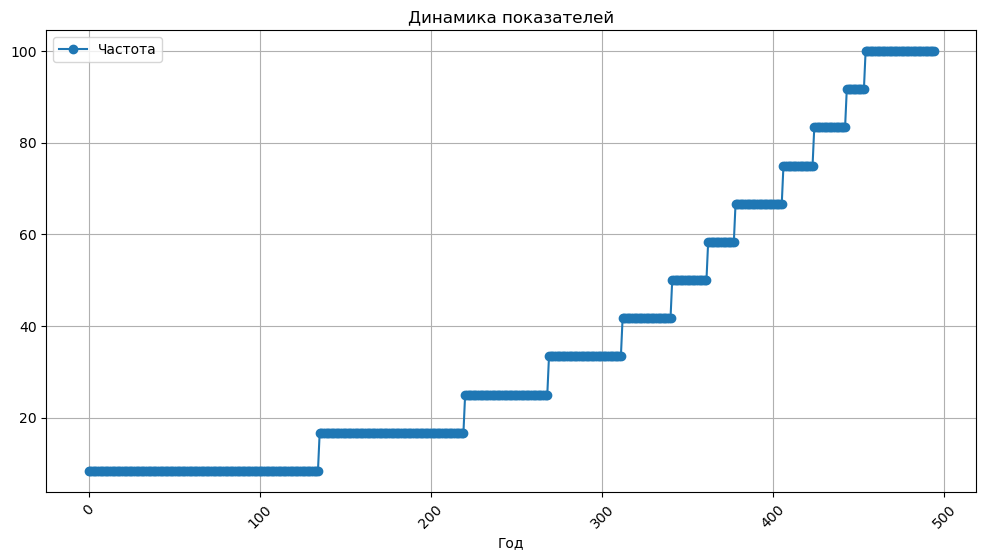

In [25]:
plt.figure(figsize=(12, 6))
# Рисуем линии
plt.plot(sales_count.index, sales_count['Частота'], label='Частота', marker='o')
#plt.plot(df_all_itog_year['Год'], df_all_itog_year['Приход'], label='Приход', marker='o')

# Добавляем подписи
plt.xlabel('Год')
#plt.ylabel('Расход')
plt.title('Динамика показателей')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [40]:
sales_count_0 = sales_count.groupby('Код')['Кол_во_продаж'].value_count()
sales_count_0

Код          Кол_во_продаж
00-00000184  10               1
00-00000185  12               1
00-00000186  11               1
00-00000187  8                1
00-00000188  8                1
                             ..
0Т-00053343  2                1
0Т-00053868  1                1
0Т-00054108  1                1
0Т-00054109  1                1
0Т-00054517  1                1
Name: count, Length: 495, dtype: int64

# Чтобы с нулевыми значениями

In [55]:
# Сначала получаем все уникальные товары
all_products = valtec_df_common_12['Код'].unique()

# Считаем, сколько месяцев с ненулевыми продажами
non_zero_sales = valtec_df_common_12[valtec_df_common_12['Расход_шт'] > 0] \
    .groupby('Код')['Расход_шт'].count()

# Создаём DataFrame: все товары и их количество месяцев с продажами (если не было — будет 0)
sales_count = pd.DataFrame({'Код': all_products})
sales_count['Кол_во_продаж'] = sales_count['Код'].map(non_zero_sales).fillna(0).astype(int)


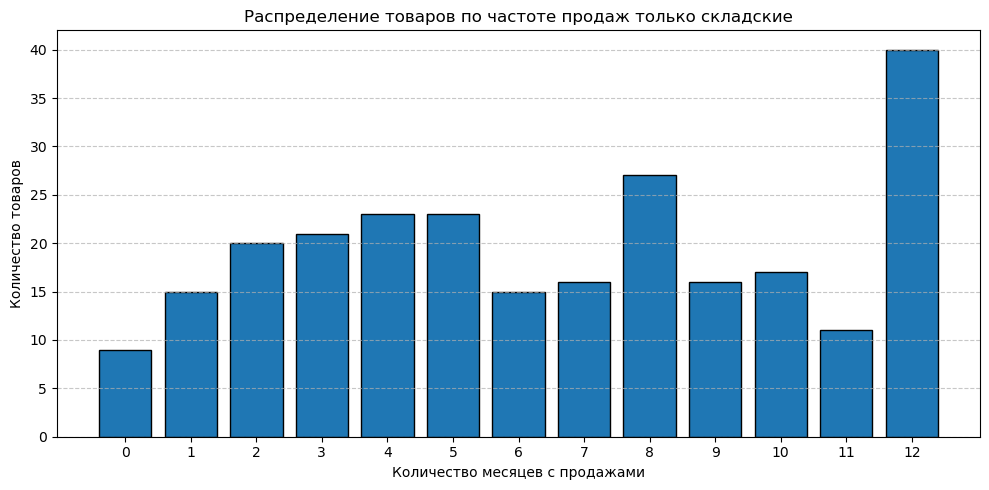

In [56]:
# Группируем: сколько товаров с каждой частотой
freq_counts = sales_count['Кол_во_продаж'].value_counts()

# Сортируем по количеству товаров (values), а не по частоте (index)
freq_counts_sorted = freq_counts.sort_values()

# Строим график
plt.figure(figsize=(10, 5))
plt.bar(freq_counts_sorted.index, freq_counts_sorted.values, edgecolor='black')
plt.xlabel('Количество месяцев с продажами')
plt.ylabel('Количество товаров')
plt.title('Распределение товаров по частоте продаж только складские')
plt.xticks(freq_counts_sorted.index)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
#plt.hist(sales_count['Кол_во_продаж'], bins=20, edgecolor='black')


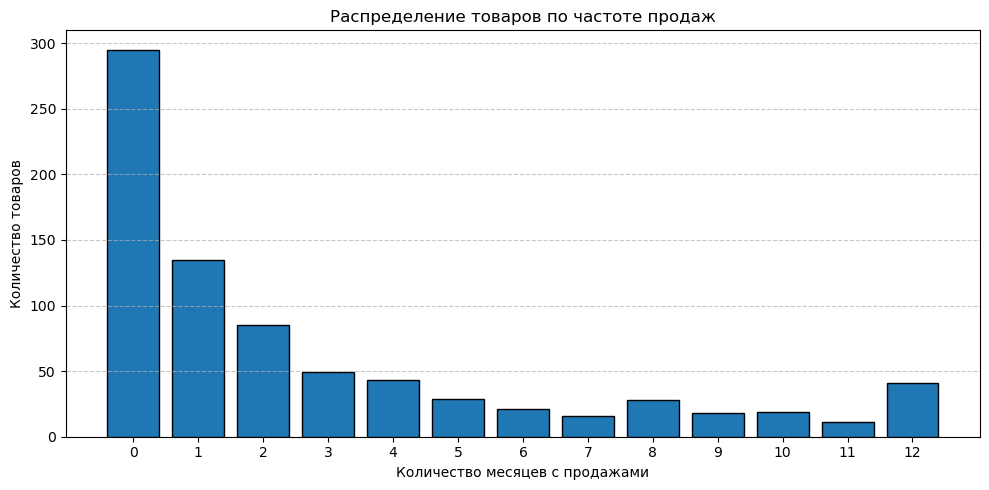

In [46]:
# Группируем: сколько товаров с каждой частотой
freq_counts = sales_count['Кол_во_продаж'].value_counts()

# Сортируем по количеству товаров (values), а не по частоте (index)
freq_counts_sorted = freq_counts.sort_values()

# Строим график
plt.figure(figsize=(10, 5))
plt.bar(freq_counts_sorted.index, freq_counts_sorted.values, edgecolor='black')
plt.xlabel('Количество месяцев с продажами')
plt.ylabel('Количество товаров')
plt.title('Распределение товаров по частоте продаж')
plt.xticks(freq_counts_sorted.index)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
#plt.hist(sales_count['Кол_во_продаж'], bins=20, edgecolor='black')


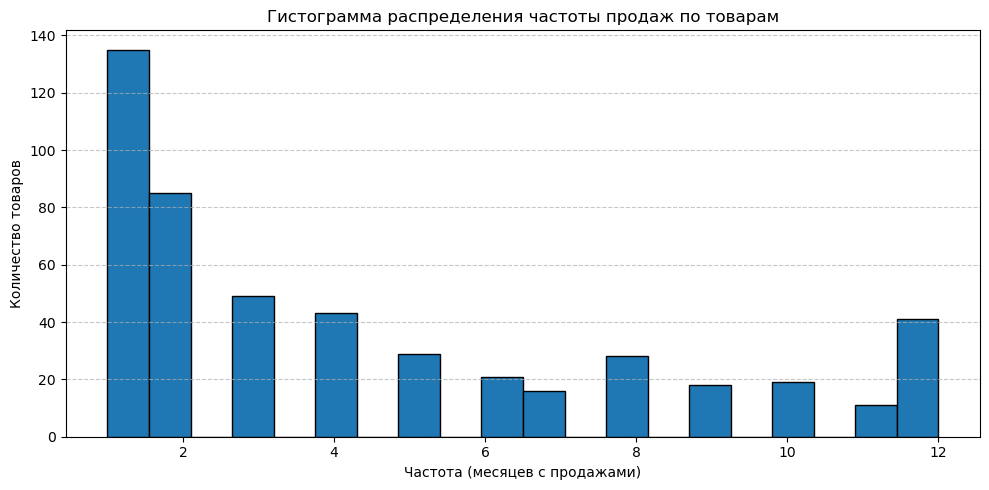

In [44]:

plt.figure(figsize=(10, 5))
plt.hist(sales_count['Кол_во_продаж'], bins=20, edgecolor='black')
plt.xlabel('Частота (месяцев с продажами)')
plt.ylabel('Количество товаров')
plt.title('Гистограмма распределения частоты продаж по товарам')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
